# Customer Churn Prediction: Logistic Regression vs Gradient Boosting

**Dataset:** Kaggle *Customer Churn Prediction Dataset – 1M* (`customer_churn_1M.csv`, 1,000,000 customers, about 9.9% churn).

**Research question:** Does a gradient-boosted tree model rank customers by churn risk better than a regularised logistic regression (primary metric: PR-AUC on a held-out test set), and what does it capture in a budget-limited retention campaign (recall and lift in the top 10% of customers)?

The notebook follows `methodology.md` step by step:
1. Load and audit the data
2. Clean it (stateless rules first, train-fitted steps inside the pipeline)
3. Split into train, validation and test sets
4. Engineer features
5. Train and tune two models
6. Evaluate on the untouched test set
7. Summarise the findings

**Setup:** the dataset is included in the repository as `data/customer_churn_1M.csv.gz` (40 MB, read directly by pandas); the raw 170 MB CSV is too large for GitHub, so the compressed copy is committed instead. Placing the original `data/customer_churn_1M.csv` there also works.

In [1]:
import os
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, roc_auc_score, f1_score, precision_score,
                             recall_score, brier_score_loss, precision_recall_curve,
                             confusion_matrix, ConfusionMatrixDisplay)
from sklearn.model_selection import (train_test_split, GridSearchCV, RandomizedSearchCV,
                                     StratifiedKFold)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)
SEED = 42
rng = np.random.default_rng(SEED)
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 50)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

CANDIDATE_PATHS = ["data/customer_churn_1M.csv.gz", "data/customer_churn_1M.csv", "customer_churn_1M.csv", "../data/customer_churn_1M.csv"]
DATA_PATH = next((p for p in CANDIDATE_PATHS if os.path.exists(p)), None)
if DATA_PATH is None:
    raise FileNotFoundError("Dataset not found. Expected data/customer_churn_1M.csv.gz (included in the repo) or data/customer_churn_1M.csv (Kaggle).")

print(f"pandas {pd.__version__} | numpy {np.__version__} | scikit-learn {sklearn.__version__}")
print("Using data file:", DATA_PATH)

pandas 3.0.5 | numpy 2.5.3 | scikit-learn 1.9.1
Using data file: data/customer_churn_1M.csv.gz


## 1. Data loading and audit

In [2]:
t0 = time.time()
df_raw = pd.read_csv(DATA_PATH)
print(f"Loaded {df_raw.shape[0]:,} rows x {df_raw.shape[1]} columns in {time.time() - t0:.1f}s "
      f"({df_raw.memory_usage(deep=True).sum() / 1e6:,.0f} MB in memory)")
df_raw.head()

Loaded 1,000,000 rows x 32 columns in 2.6s (668 MB in memory)


,customer_id,signup_date,age,gender,annual_income,education,marital_status,dependents,tenure,contract,payment_method,paperless_billing,senior_citizen,monthlycharges,totalcharges,num_services,has_phone_service,has_internet_service,has_online_security,has_online_backup,has_device_protection,has_tech_support,has_streaming_tv,has_streaming_movies,customer_satisfaction,num_complaints,num_service_calls,late_payments,avg_monthly_gb,days_since_last_interaction,credit_score,churn
0,CUST0000000001,2022-12-12 12:53:58.199463,43,Female,55085.25,college,married,1,2,two_year,electronic_check,Yes,0,67.20,144.39,1,1,1,0,0,1,1,1,1,9.0,0.0,0,0,109.63,16,NaN,0
1,CUST0000000002,2022-01-13 12:53:58.199973,18,Male,60786.11,master,married,1,22,one_year,bank_transfer,Yes,0,71.54,1602.22,2,0,1,0,1,0,0,0,1,7.0,0.0,3,1,63.25,134,585.0,0
2,CUST0000000003,2023-09-04 12:53:58.199985,38,Female,73184.32,high_school,widowed,0,3,two_year,credit_card,No,0,112.20,328.81,4,1,1,0,0,1,1,1,0,6.0,1.0,1,0,47.77,11,632.0,0
3,CUST0000000004,2022-06-27 12:53:58.199992,44,Male,40923.78,high_school,married,1,6,two_year,bank_transfer,Yes,0,107.49,643.45,3,1,1,0,0,1,1,0,1,5.0,2.0,2,1,50.82,6,569.0,0
4,CUST0000000005,2022-12-08 12:53:58.199999,45,Female,36400.94,bachelor,single,0,9,two_year,credit_card,Yes,0,110.05,648.79,3,0,1,0,0,0,0,0,1,8.0,1.0,1,0,16.74,18,657.0,0


In [3]:
audit = pd.DataFrame({
    "dtype": df_raw.dtypes.astype(str),
    "missing": df_raw.isna().sum(),
    "missing_%": (df_raw.isna().mean() * 100).round(2),
    "n_unique": df_raw.nunique(),
})
print("Columns with missing values:")
print(audit[audit["missing"] > 0].to_string())
print()
print(f"Duplicate customer_id values: {df_raw['customer_id'].duplicated().sum():,}")
print(f"Duplicate rows (ignoring id): {df_raw.drop(columns='customer_id').duplicated().sum():,}")
print()
print("Target balance (churn):")
print(df_raw["churn"].value_counts().rename("count").to_frame().assign(share=lambda d: (d["count"] / len(df_raw)).round(4)))

Columns with missing values:
                         dtype  missing  missing_%  n_unique
annual_income          float64    29959       3.00    856556
customer_satisfaction  float64    19921       1.99         9
num_complaints         float64    29906       2.99         8
avg_monthly_gb         float64    50012       5.00     27482
credit_score           float64    40395       4.04       539

Duplicate customer_id values: 0


Duplicate rows (ignoring id): 0

Target balance (churn):
        count   share
churn                
0      900773  0.9008
1       99227  0.0992


In [4]:
num_summary = df_raw.select_dtypes("number").describe(percentiles=[.01, .5, .99]).T
print(num_summary[["min", "1%", "50%", "99%", "max"]].round(2).to_string())
print()
print("Potential outliers flagged by the audit:")
print(f"  monthlycharges > 200 : {(df_raw['monthlycharges'] > 200).sum():,} rows (median is {df_raw['monthlycharges'].median():.1f})")
print(f"  avg_monthly_gb > 300 : {(df_raw['avg_monthly_gb'] > 300).sum():,} rows (median is {df_raw['avg_monthly_gb'].median():.1f})")

                                 min        1%       50%        99%        max
age                             18.0     18.00     44.00      79.00      90.00
annual_income                20000.0  20000.00  48954.60  197747.89  250000.00
dependents                       0.0      0.00      1.00       3.00       5.00
tenure                           1.0      1.00     16.00      72.00      72.00
senior_citizen                   0.0      0.00      0.00       1.00       1.00
monthlycharges                  20.0     36.91     85.48     145.20     854.96
totalcharges                    16.3     53.67   1249.75    7785.64   16252.86
num_services                     1.0      1.00      2.00       6.00       6.00
has_phone_service                0.0      0.00      1.00       1.00       1.00
has_internet_service             0.0      0.00      1.00       1.00       1.00
has_online_security              0.0      0.00      0.00       1.00       1.00
has_online_backup                0.0      0.00      

## 2. Data cleaning

**Stateless rules (safe to apply before splitting):** drop the identifier, standardise text, convert Yes/No flags, parse the date, and null out values that break domain rules. **Steps that learn a statistic** (outlier limits and medians) are implemented as transformers and fitted on the training split only, so no information leaks from validation or test data.

In [5]:
CAT_TEXT_COLS = ["gender", "education", "marital_status", "contract", "payment_method", "paperless_billing"]

# Plausible ranges; anything outside becomes missing (and is later imputed on train statistics)
DOMAIN_RULES = {
    "age": (18, 100), "tenure": (1, 120), "customer_satisfaction": (1, 10), "credit_score": (300, 850),
    "annual_income": (0, np.inf), "monthlycharges": (0, np.inf), "totalcharges": (0, np.inf),
    "num_complaints": (0, np.inf), "num_service_calls": (0, np.inf), "late_payments": (0, np.inf),
    "avg_monthly_gb": (0, np.inf), "days_since_last_interaction": (0, np.inf),
}


def clean_raw(frame):
    """Stateless cleaning: identical rules can be applied to any new data."""
    df = frame.drop_duplicates(subset="customer_id").drop(columns="customer_id").copy()

    # Formatting: strip/lower-case text, Yes/No -> 1/0
    for col in CAT_TEXT_COLS:
        df[col] = df[col].astype(str).str.strip().str.lower()
    df["paperless_billing"] = df["paperless_billing"].map({"yes": 1, "no": 0}).astype("int8")

    # Dates: parse and derive calendar features
    signup = pd.to_datetime(df["signup_date"], errors="coerce")
    df["signup_year"] = signup.dt.year
    df["signup_month"] = signup.dt.month
    df = df.drop(columns="signup_date")

    # Domain validity rules
    report = {}
    for col, (lo, hi) in DOMAIN_RULES.items():
        bad = (df[col] < lo) | (df[col] > hi)
        report[col] = int(bad.sum())
        if bad.any():
            df[col] = df[col].astype("float64")
            df.loc[bad, col] = np.nan
    return df, report


df, violations = clean_raw(df_raw)
print("Rows after cleaning:", f"{len(df):,}", "| columns:", df.shape[1])
print("Domain-rule violations set to missing:", {k: v for k, v in violations.items() if v} or "none")

# Logical consistency: add-on services require internet service
addon_cols = ["has_online_security", "has_online_backup", "has_device_protection", "has_tech_support",
              "has_streaming_tv", "has_streaming_movies"]
inconsistent = ((df["has_internet_service"] == 0) & (df[addon_cols].sum(axis=1) > 0)).sum()
print("Rows with add-ons but no internet service:", inconsistent)
flag_total = df[["has_phone_service", "has_internet_service"] + addon_cols].sum(axis=1)
print(f"num_services equals the sum of service flags in only {(flag_total == df['num_services']).mean():.1%} of rows "
      "(kept as a separate signal; n_addons is recomputed from the flags)")

Rows after cleaning: 1,000,000 | columns: 32
Domain-rule violations set to missing: none
Rows with add-ons but no internet service: 128780
num_services equals the sum of service flags in only 12.0% of rows (kept as a separate signal; n_addons is recomputed from the flags)


### Train / validation / test split

A stratified 70 / 10 / 20 split keeps the churn rate identical in every part. The **validation set** is used to choose the decision threshold; the **test set** is used once, at the end.

In [6]:
X = df.drop(columns="churn")
y = df["churn"].astype(int)

X_trainval, X_test, y_trainval, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=SEED)
X_train, X_val, y_train, y_val = train_test_split(X_trainval, y_trainval, test_size=0.125,
                                                  stratify=y_trainval, random_state=SEED)
del X_trainval, y_trainval

for name, part in [("train", y_train), ("validation", y_val), ("test", y_test)]:
    print(f"{name:<11}: {len(part):>8,} rows | churn rate {part.mean():.4f}")

train      :  700,000 rows | churn rate 0.0992
validation :  100,000 rows | churn rate 0.0992
test       :  200,000 rows | churn rate 0.0992


## 3. Feature engineering and preprocessing pipeline

Three custom transformers plus a `ColumnTransformer` form one pipeline that is fitted on the training data only:

1. `Winsorizer` clips extreme values at the training 0.5th / 99.5th percentiles.
2. `MedianImputerWithFlags` fills missing values with training medians and adds `<column>_missing` indicators.
3. `FeatureBuilder` creates the derived variables listed in `methodology.md` (billing ratios, support intensity, service counts, satisfaction and inactivity flags, tenure bands, log transforms) and ordinal-encodes `education` and `contract`.
4. `ColumnTransformer` one-hot encodes `gender`, `marital_status` and `payment_method`, and standardises numeric features for logistic regression only.

In [7]:
WINSOR_COLS = ["monthlycharges", "totalcharges", "avg_monthly_gb", "annual_income"]
IMPUTE_COLS = ["annual_income", "customer_satisfaction", "num_complaints", "avg_monthly_gb", "credit_score"]
CAT_COLS = ["gender", "marital_status", "payment_method"]
EDU_ORDER = {"high_school": 1, "college": 2, "bachelor": 3, "master": 4, "phd": 5}
CONTRACT_MONTHS = {"month_to_month": 1, "one_year": 12, "two_year": 24}


class Winsorizer(BaseEstimator, TransformerMixin):
    """Clip columns to quantile limits learned on the training data."""
    def __init__(self, cols, lower=0.005, upper=0.995):
        self.cols, self.lower, self.upper = cols, lower, upper

    def fit(self, X, y=None):
        self.bounds_ = {c: (X[c].quantile(self.lower), X[c].quantile(self.upper)) for c in self.cols}
        return self

    def transform(self, X):
        X = X.copy()
        for c, (lo, hi) in self.bounds_.items():
            X[c] = X[c].clip(lo, hi)
        return X


class MedianImputerWithFlags(BaseEstimator, TransformerMixin):
    """Median imputation (train medians) plus a missing-indicator column for columns with gaps in train."""
    def __init__(self, cols):
        self.cols = cols

    def fit(self, X, y=None):
        self.medians_ = X[self.cols].median()
        self.flag_cols_ = [c for c in self.cols if X[c].isna().any()]
        return self

    def transform(self, X):
        X = X.copy()
        for c in self.flag_cols_:
            X[f"{c}_missing"] = X[c].isna().astype("int8")
        X[self.cols] = X[self.cols].fillna(self.medians_)
        return X


class FeatureBuilder(BaseEstimator, TransformerMixin):
    """Stateless feature engineering (see methodology.md, section 4)."""
    def fit(self, X, y=None):
        self.n_features_in_ = X.shape[1]   # marks the transformer as fitted for scikit-learn
        return self

    def transform(self, X):
        d = X.copy()
        d["avg_billed_per_month"] = d["totalcharges"] / d["tenure"]
        d["billing_ratio"] = (d["totalcharges"] / (d["tenure"] * d["monthlycharges"])).clip(0, 2)
        d["charge_to_income"] = 12 * d["monthlycharges"] / d["annual_income"]
        d["n_addons"] = d[["has_online_security", "has_online_backup", "has_device_protection",
                           "has_tech_support", "has_streaming_tv", "has_streaming_movies"]].sum(axis=1)
        d["support_contacts"] = d["num_complaints"] + d["num_service_calls"]
        d["complaints_per_month"] = d["num_complaints"] / d["tenure"]
        d["calls_per_month"] = d["num_service_calls"] / d["tenure"]
        d["low_satisfaction"] = (d["customer_satisfaction"] <= 4).astype("int8")
        d["inactive_90d"] = (d["days_since_last_interaction"] > 90).astype("int8")
        d["tenure_bucket"] = pd.cut(d["tenure"], [0, 6, 12, 24, 48, 10_000], labels=False).astype("int8")
        for c in ["totalcharges", "avg_monthly_gb", "annual_income"]:
            d[f"log_{c}"] = np.log1p(d[c])
        d["education_level"] = d["education"].map(EDU_ORDER).fillna(3).astype("int8")
        d["contract_months"] = d["contract"].map(CONTRACT_MONTHS).fillna(12).astype("int16")
        return d.drop(columns=["education", "contract"])


# Learn the output column names once (on a slice of the training data) to configure the encoder
_probe = Pipeline([("w", Winsorizer(WINSOR_COLS)), ("i", MedianImputerWithFlags(IMPUTE_COLS)),
                   ("f", FeatureBuilder())]).fit_transform(X_train.head(100_000))
NUM_COLS = [c for c in _probe.columns if c not in CAT_COLS]
print(f"{len(NUM_COLS)} numeric features + {len(CAT_COLS)} categorical columns (one-hot encoded)")
print("Engineered / added columns:", [c for c in NUM_COLS if c not in X_train.columns])


def make_pipeline(estimator, scale_numeric):
    encode = ColumnTransformer([
        ("num", StandardScaler() if scale_numeric else "passthrough", NUM_COLS),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT_COLS),
    ])
    return Pipeline([("winsor", Winsorizer(WINSOR_COLS)),
                     ("impute", MedianImputerWithFlags(IMPUTE_COLS)),
                     ("features", FeatureBuilder()),
                     ("encode", encode),
                     ("model", estimator)])

46 numeric features + 3 categorical columns (one-hot encoded)
Engineered / added columns: ['annual_income_missing', 'customer_satisfaction_missing', 'num_complaints_missing', 'avg_monthly_gb_missing', 'credit_score_missing', 'avg_billed_per_month', 'billing_ratio', 'charge_to_income', 'n_addons', 'support_contacts', 'complaints_per_month', 'calls_per_month', 'low_satisfaction', 'inactive_90d', 'tenure_bucket', 'log_totalcharges', 'log_avg_monthly_gb', 'log_annual_income', 'education_level', 'contract_months']


In [8]:
# Quick look at the engineered features: correlation with churn on the TRAINING data only
eda = Pipeline([("w", Winsorizer(WINSOR_COLS)), ("i", MedianImputerWithFlags(IMPUTE_COLS)),
                ("f", FeatureBuilder())]).fit(X_train).transform(X_train.sample(200_000, random_state=SEED))
corr = eda[NUM_COLS].corrwith(y_train.loc[eda.index]).sort_values(key=np.abs, ascending=False)
print("Strongest linear correlations with churn (train sample):")
print(corr.head(10).round(4).to_string())
print()
print("Churn rate by contract type (train):")
print(y_train.groupby(X_train["contract"]).agg(["mean", "size"]).round(4).to_string())
del eda

Strongest linear correlations with churn (train sample):
contract_months         -0.1322
support_contacts         0.0906
customer_satisfaction   -0.0811
num_complaints           0.0793
num_service_calls        0.0776
low_satisfaction         0.0723
late_payments            0.0456
has_tech_support        -0.0431
complaints_per_month     0.0381
calls_per_month          0.0360

Churn rate by contract type (train):
                  mean    size
contract                      
month_to_month  0.2653   13916
one_year        0.1268  385540
two_year        0.0562  300544


## 4. Models, training and hyperparameter configuration

Two models are trained, plus a no-skill baseline:

| Model | Hyperparameters tuned |
|---|---|
| Logistic Regression (L2) | regularisation strength `C` in {0.01, 0.1, 1, 10}, `class_weight` in {None, balanced} |
| `HistGradientBoostingClassifier` | learning rate, max leaf nodes, max depth, min samples per leaf, L2 regularisation (randomised search; early stopping on an internal 10% split) |

Tuning uses **stratified 3-fold cross-validation on a 100,000-row subsample of the training split**, optimising PR-AUC (`average_precision`). The best configuration is then refitted on the **full training split**.

In [9]:
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
X_tune, _, y_tune, _ = train_test_split(X_train, y_train, train_size=100_000, stratify=y_train, random_state=SEED)

# ---- No-skill baseline -------------------------------------------------
print(f"No-skill PR-AUC on test = churn prevalence = {y_test.mean():.4f}; ROC-AUC = 0.5")

# ---- Model 1: Logistic Regression -------------------------------------
lr_pipe = make_pipeline(LogisticRegression(solver="lbfgs", max_iter=500, random_state=SEED), scale_numeric=True)
lr_grid = {"model__C": [0.01, 0.1, 1.0, 10.0], "model__class_weight": [None, "balanced"]}

t0 = time.time()
lr_search = GridSearchCV(lr_pipe, lr_grid, scoring="average_precision", cv=cv, n_jobs=2, refit=False, verbose=0)
lr_search.fit(X_tune, y_tune)
print(f"\nLogistic regression grid search done in {time.time() - t0:.0f}s")
print("Best params:", lr_search.best_params_, "| CV PR-AUC:", round(lr_search.best_score_, 4))

t0 = time.time()
lr_model = clone(lr_pipe).set_params(**lr_search.best_params_).fit(X_train, y_train)
print(f"Final logistic regression fitted on {len(X_train):,} rows in {time.time() - t0:.0f}s")

No-skill PR-AUC on test = churn prevalence = 0.0992; ROC-AUC = 0.5



Logistic regression grid search done in 7s
Best params: {'model__C': 10.0, 'model__class_weight': None} | CV PR-AUC: 0.2035


Final logistic regression fitted on 700,000 rows in 4s


In [10]:
# ---- Model 2: Histogram Gradient Boosting ------------------------------
hgb_pipe = make_pipeline(
    HistGradientBoostingClassifier(max_iter=300, early_stopping=True, validation_fraction=0.1,
                                   n_iter_no_change=20, random_state=SEED),
    scale_numeric=False)
hgb_dist = {
    "model__learning_rate": [0.03, 0.05, 0.08, 0.12],
    "model__max_leaf_nodes": [15, 31, 63],
    "model__max_depth": [None, 4, 6, 8],
    "model__min_samples_leaf": [20, 100, 500],
    "model__l2_regularization": [0.0, 1.0, 10.0],
}

t0 = time.time()
hgb_search = RandomizedSearchCV(hgb_pipe, hgb_dist, n_iter=8, scoring="average_precision", cv=cv,
                                n_jobs=2, refit=False, random_state=SEED, verbose=0)
hgb_search.fit(X_tune, y_tune)
print(f"Gradient boosting randomised search done in {time.time() - t0:.0f}s")
print("Best params:", hgb_search.best_params_, "| CV PR-AUC:", round(hgb_search.best_score_, 4))

cvres = pd.DataFrame(hgb_search.cv_results_).sort_values("rank_test_score")
print("\nTop 3 configurations (mean CV PR-AUC):")
print(cvres[["mean_test_score", "std_test_score"] + [c for c in cvres.columns if c.startswith("param_")]].head(3).round(4).to_string(index=False))

t0 = time.time()
hgb_model = clone(hgb_pipe).set_params(**hgb_search.best_params_).fit(X_train, y_train)
print(f"\nFinal gradient boosting fitted on {len(X_train):,} rows in {time.time() - t0:.0f}s "
      f"({hgb_model.named_steps['model'].n_iter_} boosting iterations after early stopping)")

Gradient boosting randomised search done in 32s
Best params: {'model__min_samples_leaf': 20, 'model__max_leaf_nodes': 15, 'model__max_depth': None, 'model__learning_rate': 0.05, 'model__l2_regularization': 1.0} | CV PR-AUC: 0.2

Top 3 configurations (mean CV PR-AUC):
 mean_test_score  std_test_score  param_model__min_samples_leaf  param_model__max_leaf_nodes param_model__max_depth  param_model__learning_rate  param_model__l2_regularization
          0.2000          0.0024                             20                           15                   None                        0.05                             1.0
          0.1997          0.0025                            100                           15                      4                        0.03                             1.0
          0.1991          0.0020                             20                           15                      6                        0.12                            10.0



Final gradient boosting fitted on 700,000 rows in 19s (197 boosting iterations after early stopping)


## 5. Evaluation

**Threshold selection (validation set only).** Each model outputs a churn probability. The classification threshold that maximises F1 on the validation set is selected and then frozen before the test set is scored.

**Test-set metrics.**
- **PR-AUC** (primary ranking metric)
- **F1, precision, recall** at the validation-tuned threshold
- **Recall@top-10% and lift@top-10%** (budget-limited campaign)
- **ROC-AUC** and **Brier score**

Uncertainty is estimated with a 100-resample paired bootstrap of the test set.

In [11]:
def best_f1_threshold(y_true, p):
    prec, rec, thr = precision_recall_curve(y_true, p)
    f1 = 2 * prec[:-1] * rec[:-1] / np.clip(prec[:-1] + rec[:-1], 1e-12, None)
    return float(thr[np.argmax(f1)])


def top_fraction_metrics(y_true, p, frac=0.10):
    k = int(len(p) * frac)
    top = np.argsort(-p)[:k]
    hits = y_true[top].sum()
    return hits / y_true.sum(), (hits / k) / y_true.mean()   # recall@k, lift@k


y_val_a, y_test_a = y_val.to_numpy(), y_test.to_numpy()
models = {"Logistic Regression": lr_model, "Gradient Boosting": hgb_model}
p_val = {n: m.predict_proba(X_val)[:, 1] for n, m in models.items()}
p_test = {n: m.predict_proba(X_test)[:, 1] for n, m in models.items()}
thresholds = {n: best_f1_threshold(y_val_a, p_val[n]) for n in models}

rows = []
for n in models:
    p, thr = p_test[n], thresholds[n]
    pred = (p >= thr).astype(int)
    rec10, lift10 = top_fraction_metrics(y_test_a, p)
    rows.append({
        "Model": n,
        "PR-AUC": average_precision_score(y_test_a, p),
        "ROC-AUC": roc_auc_score(y_test_a, p),
        "F1": f1_score(y_test_a, pred),
        "Precision": precision_score(y_test_a, pred, zero_division=0),
        "Recall": recall_score(y_test_a, pred),
        "Recall@top10%": rec10,
        "Lift@top10%": lift10,
        "Brier": brier_score_loss(y_test_a, p),
        "Threshold": thr,
    })
results = pd.DataFrame(rows).set_index("Model")

print("=" * 100)
print(f"TEST-SET RESULTS ({len(y_test_a):,} customers, churn rate {y_test_a.mean():.4f}; no-skill PR-AUC = {y_test_a.mean():.4f})")
print("=" * 100)
print(results.round(4).to_string())

TEST-SET RESULTS (200,000 customers, churn rate 0.0992; no-skill PR-AUC = 0.0992)
                     PR-AUC  ROC-AUC      F1  Precision  Recall  Recall@top10%  Lift@top10%   Brier  Threshold
Model                                                                                                         
Logistic Regression  0.2029   0.6848  0.2685     0.1877  0.4716         0.2453       2.4525  0.0853     0.1290
Gradient Boosting    0.2064   0.6852  0.2687     0.1994  0.4117         0.2466       2.4656  0.0852     0.1377


In [12]:
# Paired bootstrap on the test set: 95% intervals for PR-AUC / ROC-AUC and for the model difference
N_BOOT = 100
n = len(y_test_a)
boot = {"Logistic Regression": [], "Gradient Boosting": []}
boot_roc = {k: [] for k in boot}
for _ in range(N_BOOT):
    ix = rng.integers(0, n, n)
    for name in boot:
        boot[name].append(average_precision_score(y_test_a[ix], p_test[name][ix]))
        boot_roc[name].append(roc_auc_score(y_test_a[ix], p_test[name][ix]))

diff_pr = np.array(boot["Gradient Boosting"]) - np.array(boot["Logistic Regression"])
diff_roc = np.array(boot_roc["Gradient Boosting"]) - np.array(boot_roc["Logistic Regression"])
ci = lambda a: (np.percentile(a, 2.5), np.percentile(a, 97.5))

print(f"Bootstrap 95% intervals ({N_BOOT} resamples)")
for name in boot:
    lo, hi = ci(boot[name]); lo2, hi2 = ci(boot_roc[name])
    print(f"  {name:<20} PR-AUC {np.mean(boot[name]):.4f} [{lo:.4f}, {hi:.4f}] | ROC-AUC {np.mean(boot_roc[name]):.4f} [{lo2:.4f}, {hi2:.4f}]")
lo, hi = ci(diff_pr); lo2, hi2 = ci(diff_roc)
print(f"  PR-AUC difference (GB - LR):  {diff_pr.mean():+.4f} [{lo:+.4f}, {hi:+.4f}]  -> "
      f"{'interval excludes 0' if lo > 0 or hi < 0 else 'interval includes 0'}")
print(f"  ROC-AUC difference (GB - LR): {diff_roc.mean():+.4f} [{lo2:+.4f}, {hi2:+.4f}]")

Bootstrap 95% intervals (100 resamples)
  Logistic Regression  PR-AUC 0.2029 [0.1984, 0.2072] | ROC-AUC 0.6846 [0.6809, 0.6882]
  Gradient Boosting    PR-AUC 0.2065 [0.2019, 0.2114] | ROC-AUC 0.6851 [0.6813, 0.6887]
  PR-AUC difference (GB - LR):  +0.0036 [+0.0021, +0.0052]  -> interval excludes 0
  ROC-AUC difference (GB - LR): +0.0004 [-0.0003, +0.0012]


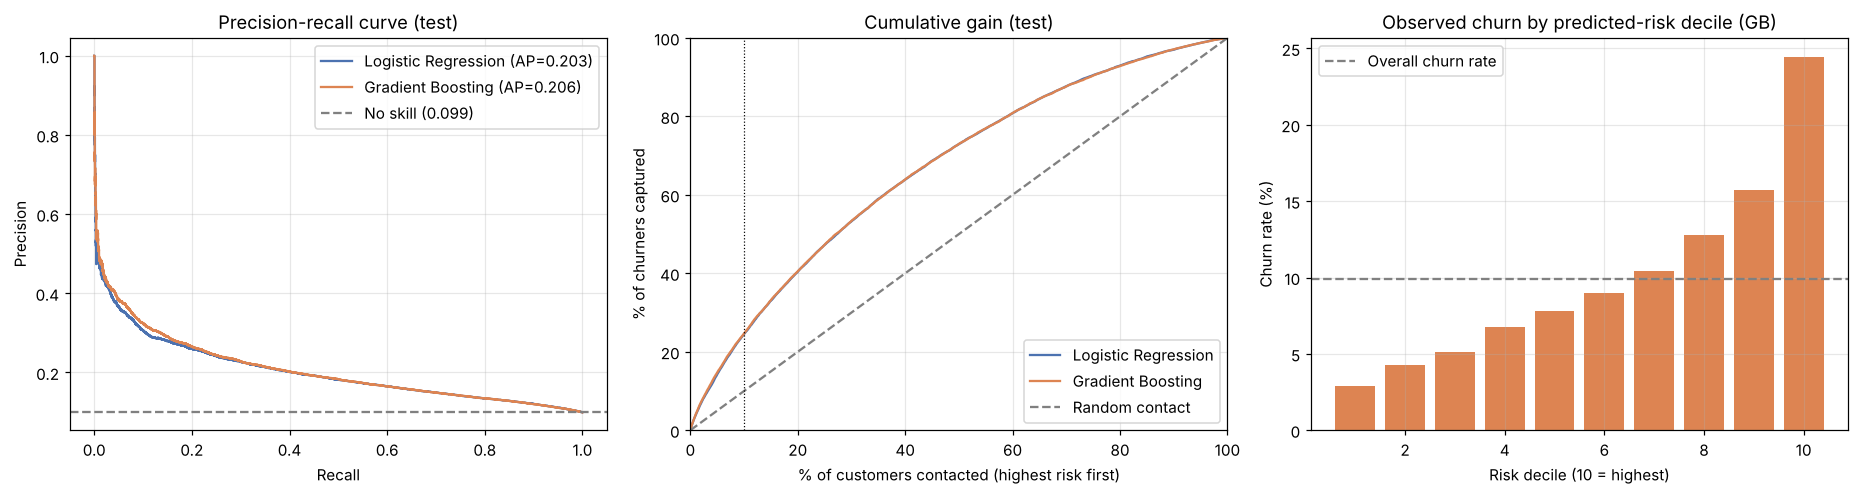

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
colors = {"Logistic Regression": "#4C72B0", "Gradient Boosting": "#DD8452"}

# (a) Precision-recall curves
for name in models:
    prec, rec, _ = precision_recall_curve(y_test_a, p_test[name])
    axes[0].plot(rec, prec, color=colors[name], label=f"{name} (AP={results.loc[name, 'PR-AUC']:.3f})")
axes[0].axhline(y_test_a.mean(), color="grey", ls="--", label=f"No skill ({y_test_a.mean():.3f})")
axes[0].set(title="Precision-recall curve (test)", xlabel="Recall", ylabel="Precision")
axes[0].legend()

# (b) Cumulative gain: share of churners captured when contacting the top-x% of customers
for name in models:
    order = np.argsort(-p_test[name])
    gain = np.cumsum(y_test_a[order]) / y_test_a.sum()
    axes[1].plot(np.arange(1, n + 1) / n * 100, gain * 100, color=colors[name], label=name)
axes[1].plot([0, 100], [0, 100], color="grey", ls="--", label="Random contact")
axes[1].axvline(10, color="black", lw=0.8, ls=":")
axes[1].set(title="Cumulative gain (test)", xlabel="% of customers contacted (highest risk first)",
            ylabel="% of churners captured", xlim=(0, 100), ylim=(0, 100))
axes[1].legend()

# (c) Calibration-style view: observed churn by predicted-risk decile (gradient boosting)
dec = pd.qcut(pd.Series(p_test["Gradient Boosting"]).rank(method="first"), 10, labels=False)
obs = pd.Series(y_test_a).groupby(dec.values).mean() * 100
axes[2].bar(obs.index + 1, obs.values, color=colors["Gradient Boosting"])
axes[2].axhline(y_test_a.mean() * 100, color="grey", ls="--", label="Overall churn rate")
axes[2].set(title="Observed churn by predicted-risk decile (GB)", xlabel="Risk decile (10 = highest)", ylabel="Churn rate (%)")
axes[2].legend()
plt.tight_layout()
plt.show()

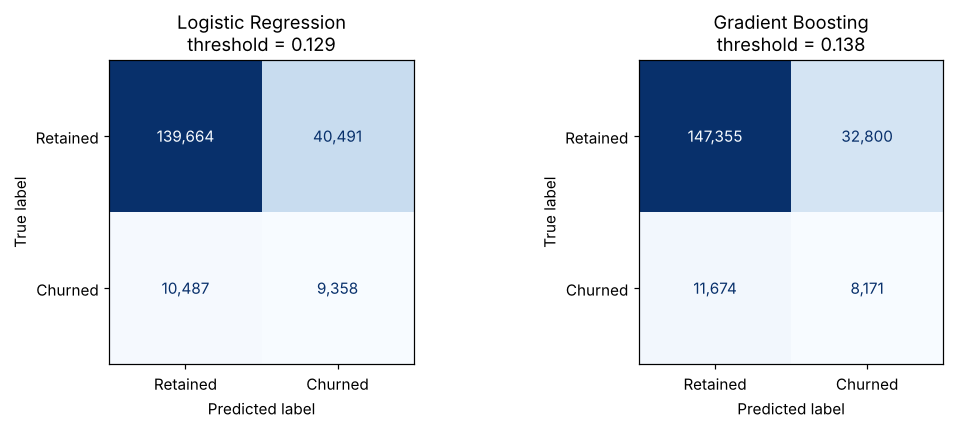

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, name in zip(axes, models):
    pred = (p_test[name] >= thresholds[name]).astype(int)
    ConfusionMatrixDisplay(confusion_matrix(y_test_a, pred), display_labels=["Retained", "Churned"]).plot(
        ax=ax, cmap="Blues", colorbar=False, values_format=",d")
    ax.set_title(f"{name}\nthreshold = {thresholds[name]:.3f}")
    ax.grid(False)
plt.tight_layout()
plt.show()

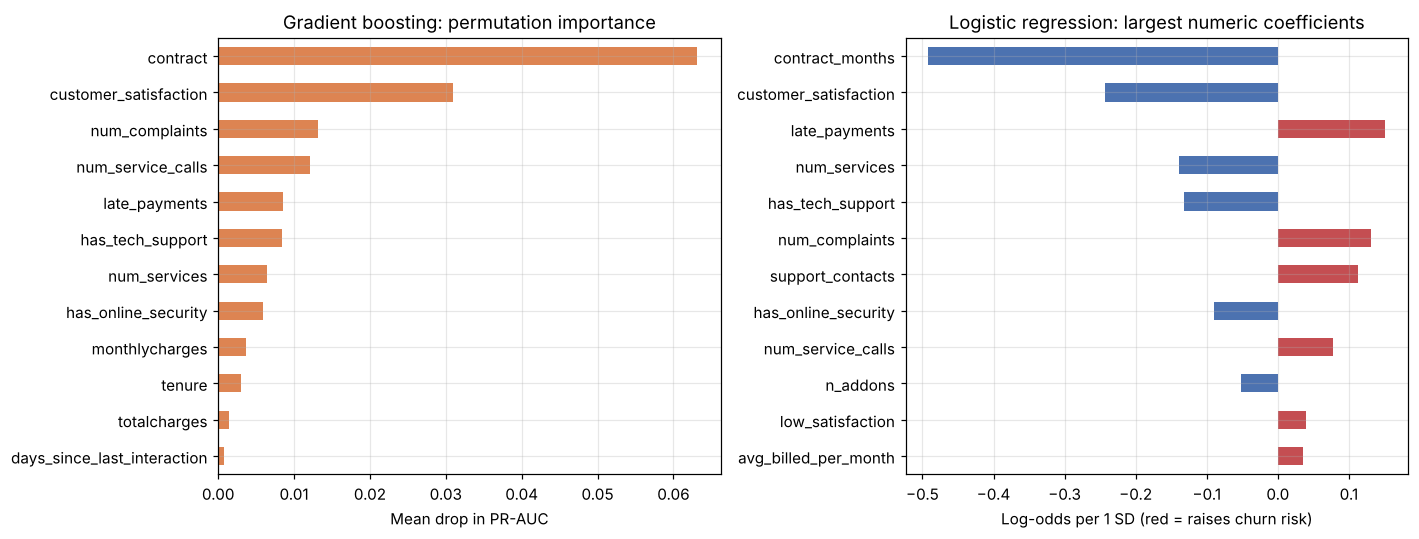

Top 6 drivers (gradient boosting): contract (0.0631), customer_satisfaction (0.0309), num_complaints (0.0132), num_service_calls (0.0122), late_payments (0.0086), has_tech_support (0.0084)


In [15]:
# Which inputs matter? Permutation importance (drop in PR-AUC) for the gradient boosting pipeline, on raw columns
sub = X_test.sample(30_000, random_state=SEED)
perm = permutation_importance(hgb_model, sub, y_test.loc[sub.index], scoring="average_precision",
                              n_repeats=3, random_state=SEED, n_jobs=2)
imp = pd.Series(perm.importances_mean, index=sub.columns).sort_values(ascending=False)

# Logistic regression: standardised coefficients (log-odds per 1 SD) of the numeric features.
# One-hot dummies are excluded because a full set of dummies is collinear with the intercept.
feat_names = list(lr_model.named_steps["encode"].get_feature_names_out())
coefs = pd.Series(lr_model.named_steps["model"].coef_[0], index=feat_names)
num_coefs = coefs[coefs.index.str.startswith("num__")]
num_coefs.index = num_coefs.index.str.replace("num__", "", regex=False)
top_coefs = num_coefs.reindex(num_coefs.abs().sort_values(ascending=False).index).head(12)[::-1]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
imp.head(12)[::-1].plot.barh(ax=axes[0], color=colors["Gradient Boosting"])
axes[0].set(title="Gradient boosting: permutation importance", xlabel="Mean drop in PR-AUC")
top_coefs.plot.barh(ax=axes[1], color=["#C44E52" if v > 0 else "#4C72B0" for v in top_coefs])
axes[1].set(title="Logistic regression: largest numeric coefficients", xlabel="Log-odds per 1 SD (red = raises churn risk)")
plt.tight_layout()
plt.show()
print("Top 6 drivers (gradient boosting):", ", ".join(f"{k} ({v:.4f})" for k, v in imp.head(6).items()))

## 6. Findings and next steps

Gradient boosting ranked customers only slightly better than logistic regression on the untouched test set (PR-AUC 0.206 versus 0.203, with an identical ROC-AUC of 0.685), a paired-bootstrap gain of +0.004 whose 95% interval excludes zero but is too small to matter in practice, while both models are roughly twice as good as chance (no-skill PR-AUC 0.099). At the validation-tuned thresholds both reach an F1 of 0.269, with logistic regression favouring recall (0.47 versus 0.41) and gradient boosting favouring precision (0.20 versus 0.19). In a campaign limited to the highest-risk 10% of customers, either model captures about 25% of all churners, a lift of roughly 2.5 over contacting customers at random. The strongest drivers were contract type (month-to-month customers churn at 27% against 6% for two-year contracts), customer satisfaction, complaints and service calls, whereas demographics and most engineered ratios added little, which suggests the usable signal in this dataset is largely additive and already captured by a linear model. With more time I would tune gradient boosting far more extensively, add XGBoost or LightGBM and a blend with logistic regression, and replace the 100,000-row tuning subsample with full-data cross-validation to confirm that the small gap is stable. I would also calibrate the probabilities, convert the top-decile results into expected profit using real retention costs and customer value, and validate on real, time-ordered customer data, because this dataset shows signs of being synthetic and its low ceiling (ROC-AUC near 0.69) may not carry over.